# 01 — Data, EDA & Training Caches

Manifests, data checks, EDA, frame step `k`, training caches, k-means anchors.

Environment (once): `pip install -r requirements.txt && pip install -e .`

In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":          # always run from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path("src").resolve()))  # use the local `vdet` package even without `pip install -e .`

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vdet.paths import P
from vdet.notebook import *   # setup_notebook, results_table, show_image, *_experiment, evaluate_preds, ...

setup_notebook(seed=42)

# Training cells are resumable: a run whose checkpoint already exists in checkpoints/ is not
# trained again (its training log and metrics are loaded). Delete the checkpoint to retrain.

Project root : /home/marko/ucu-ai-hw-2
Data         : /home/marko/ucu-ai-hw-2/data (exists=True)
Cache        : /home/marko/ucu-ai-hw-2/cache (exists=True)
Checkpoints  : /home/marko/ucu-ai-hw-2/checkpoints
Device       : NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Manifests

8 classes: `pedestrian+people→person`, `tricycle+awning-tricycle→tricycle`, `bicycle`, `car`, `van`, `truck`, `bus`, `motor`.

In [2]:
from vdet.constants import CLASS_NAMES, NUM_CLASSES
from vdet.data.manifest import build_manifests, load_manifest, load_boxes, load_ignore

if not (P.manifest_parquet.exists() and P.boxes_parquet.exists() and P.ignore_parquet.exists()):
    build_manifests(data_root=P.data, cache_root=P.cache, strict_verify=True)   # ~minutes, CPU only
else:
    print("Manifests already built: cache/manifest.parquet, boxes.parquet, ignore.parquet")

manifest_df, boxes_df, ignore_df = load_manifest(), load_boxes(), load_ignore()
print("Classes:", dict(enumerate(CLASS_NAMES)))

summary = manifest_df.groupby("split").agg(
    clips=("clip", "nunique"), frames=("image_key", "count"),
    boxes=("n_boxes", "sum"), frames_with_ignore=("n_ignore", lambda s: int((s > 0).sum())),
    ignore_regions=("n_ignore", "sum"),
).reindex(["train", "val", "test"])
display(summary)

Manifests already built: cache/manifest.parquet, boxes.parquet, ignore.parquet
Classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'van', 4: 'truck', 5: 'tricycle', 6: 'bus', 7: 'motor'}


,clips,frames,boxes,frames_with_ignore,ignore_regions
split,,,,,
train,56,24201,1105516.0,18090,63843
val,7,2846,114132.0,1434,3995
test,48,3811,0.0,0,0


## 2. Data-contract verification

In [3]:
from vdet.utils import load_json
from vdet.data.verify import run_data_verification

report_path = P.cache / "verify_data_report.json"
report = load_json(report_path) if report_path.exists() else run_data_verification()

print("Check 1 — YOLO txt vs COCO boxes, max abs error per resolution bucket (px):")
display(pd.DataFrame(report["check_1_yolo_vs_coco_buckets"]).T)
print("Check 2 — deduplicated crowd boxes vs ignore txt:", report["check_2_crowd_vs_txt"])
print("Check 3 — share of GT boxes lying inside ignore regions (IoA > 0.5), train:")
display(pd.DataFrame(report["check_3_gt_inside_ignore_per_class"]).T)
c4 = report["check_4_ignore_temporal_jumps"]
print(f"Check 4 — ignore regions jumping >20% between consecutive frames: "
      f"{c4['flagged_transitions_gt_20pct']} / {c4['total_ignore_frame_transitions']} ({c4['flagged_rate_pct']}%)")

Check 1 — YOLO txt vs COCO boxes, max abs error per resolution bucket (px):


,max_abs_px_err,boxes_checked
1344x756,0.00096,575.0
1360x765,0.00096,2375.0
1904x1071,0.00137,1084.0
1920x1080,0.00128,1034.0
2688x1512,0.00198,3055.0
2720x1530,0.00192,3638.0
3840x2160,0.00256,213.0


Check 2 — deduplicated crowd boxes vs ignore txt: {'frames_checked': 500, 'regions_checked': 1188, 'min_matched_iou': 0.999958}
Check 3 — share of GT boxes lying inside ignore regions (IoA > 0.5), train:


,total_boxes,inside_ignore_ioa_gt_0_5,share_pct
person,328701.0,4443.0,1.352
bicycle,40255.0,782.0,1.943
car,505301.0,4687.0,0.928
van,46940.0,543.0,1.157
truck,30498.0,178.0,0.584
tricycle,41349.0,460.0,1.112
bus,9653.0,37.0,0.383
motor,102819.0,603.0,0.586


Check 4 — ignore regions jumping >20% between consecutive frames: 568 / 18025 (3.15%)


### Ground truth + ignore regions, per resolution bucket

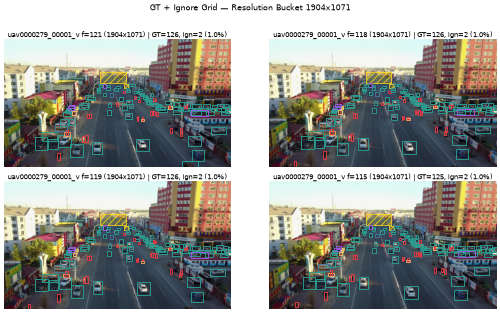

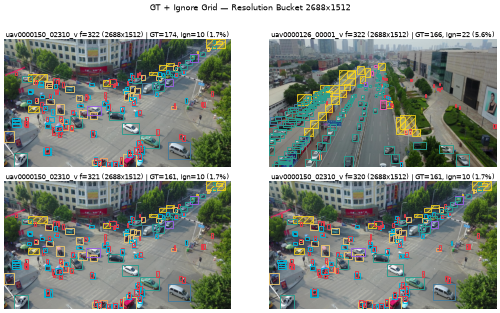

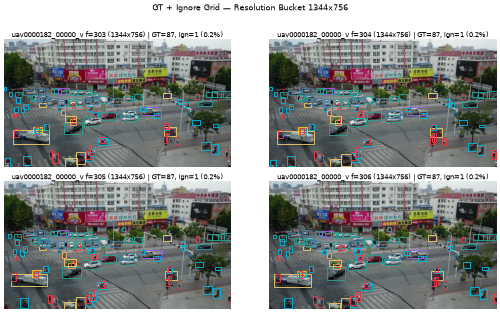

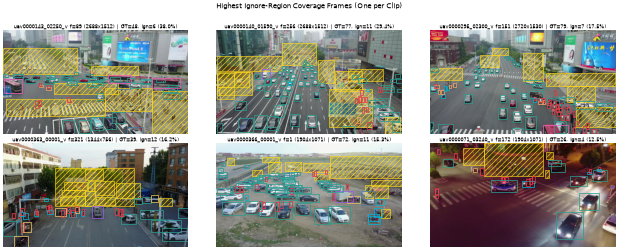

In [4]:
for name in ["gt_grid_1904x1071.png", "gt_grid_2688x1512.png", "gt_grid_1344x756.png", "ignore_worst_frames.png"]:
    show_image(name, width=850)

## 3. Exploratory data analysis

### 3.1 Class balance

In [5]:
counts = (boxes_df.groupby(["split", "cls"]).size().unstack(fill_value=0)
          .reindex(columns=range(NUM_CLASSES), fill_value=0))
counts.columns = CLASS_NAMES
share = (counts.div(counts.sum(axis=1), axis=0) * 100).round(1)
display(counts)
display(share.add_suffix(" %"))

,person,bicycle,car,van,truck,tricycle,bus,motor
split,,,,,,,,
train,328701,40255,505301,46940,30498,41349,9653,102819
val,50312,6022,31821,6842,1359,5487,264,12025


,person %,bicycle %,car %,van %,truck %,tricycle %,bus %,motor %
split,,,,,,,,
train,29.7,3.6,45.7,4.2,2.8,3.7,0.9,9.3
val,44.1,5.3,27.9,6.0,1.2,4.8,0.2,10.5


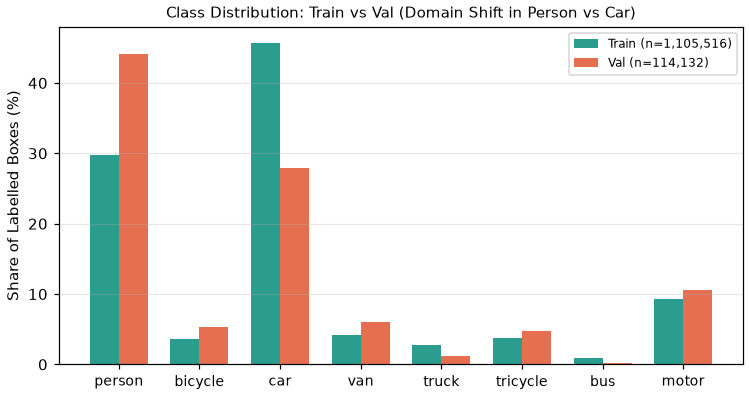

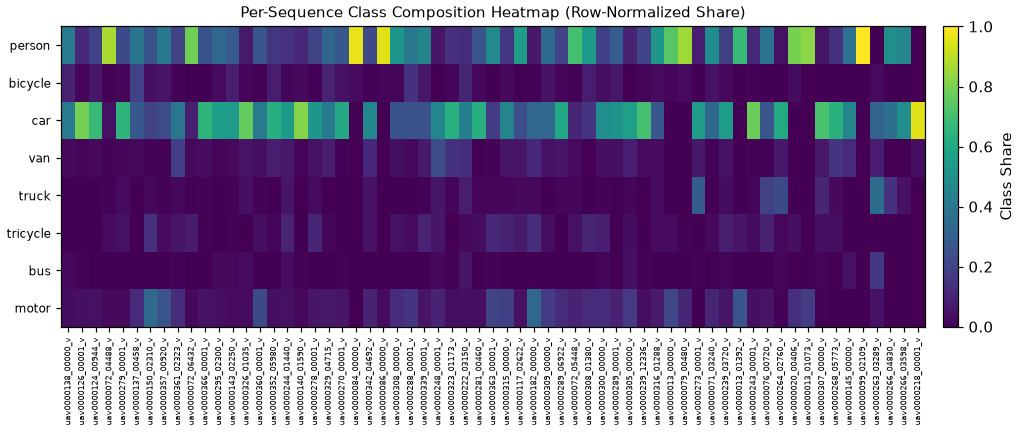

In [6]:
from vdet.data.redundancy import generate_all_eda_figures

EDA_FIGS = ["eda_class_distribution.png", "eda_clip_class_heatmap.png", "eda_object_sizes.png",
            "eda_box_wh_scatter.png", "eda_density_per_clip.png", "eda_resolutions.png",
            "eda_ignore_coverage.png", "eda_frame_step_redundancy.png"]
if not all((P.images / f).exists() for f in EDA_FIGS) or not (P.cache / "redundancy_lag_k.csv").exists():
    saved, lag_df = generate_all_eda_figures(cache_root=P.cache, images_dir=P.images)
    lag_df.to_csv(P.cache / "redundancy_lag_k.csv", index=False)

show_image("eda_class_distribution.png", 700)
show_image("eda_clip_class_heatmap.png", 800)

### 3.2 Object sizes (COCO buckets: small < 32², medium < 96², large ≥ 96²)

,small %,medium %,large %
native resolution,24.4,64.1,11.6
resized to 1280 long side,53.6,43.5,2.9


Median box side at 1280 scale: 30.6 px, 10th percentile: 16.1 px


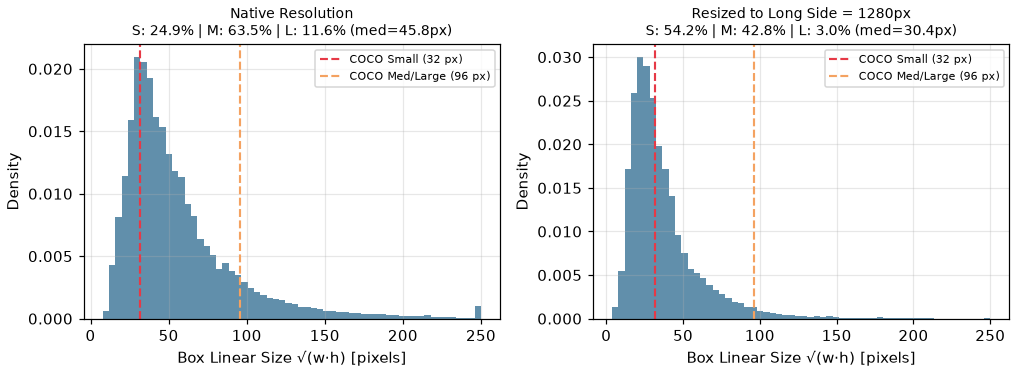

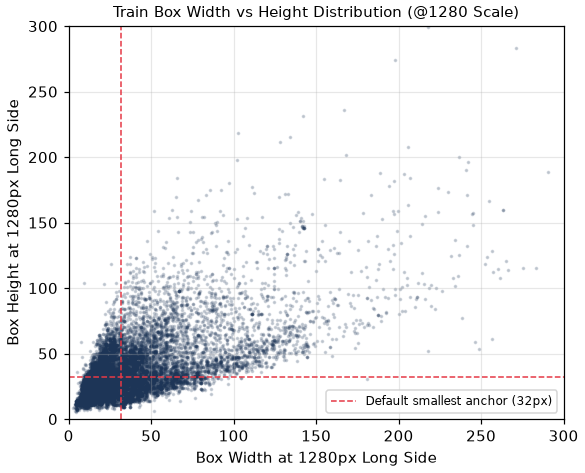

In [7]:
ann = boxes_df.merge(manifest_df[["image_key", "width", "height"]], on="image_key")
area = ann["w"] * ann["h"]
scale_1280 = 1280.0 / ann[["width", "height"]].max(axis=1)
area_1280 = area * scale_1280 ** 2

def buckets(a):
    return pd.Series({"small %": (a < 32**2).mean() * 100,
                      "medium %": ((a >= 32**2) & (a < 96**2)).mean() * 100,
                      "large %": (a >= 96**2).mean() * 100}).round(1)

display(pd.DataFrame({"native resolution": buckets(area), "resized to 1280 long side": buckets(area_1280)}).T)
print("Median box side at 1280 scale: %.1f px, 10th percentile: %.1f px"
      % (((ann["w"] * ann["h"]) ** 0.5 * scale_1280).median(), ((ann["w"] * ann["h"]) ** 0.5 * scale_1280).quantile(0.1)))
show_image("eda_object_sizes.png", 750)
show_image("eda_box_wh_scatter.png", 650)

### 3.3 Density per sequence, resolutions and ignore coverage

Densest sequences (boxes / frame):


mean    max
split clip                            
train uav0000138_00000_v  143.0  156.0
      uav0000126_00001_v  132.2  166.0
      uav0000124_00944_v  124.6  134.0
      uav0000072_04488_v  110.4  124.0
      uav0000150_02310_v  108.9  174.0
val   uav0000137_00458_v  103.4  116.0
train uav0000279_00001_v   95.3  126.0
      uav0000357_00920_v   91.9  104.0
      uav0000072_06432_v   89.9  113.0
      uav0000361_02323_v   85.8   94.0

Max boxes in a single frame: 180


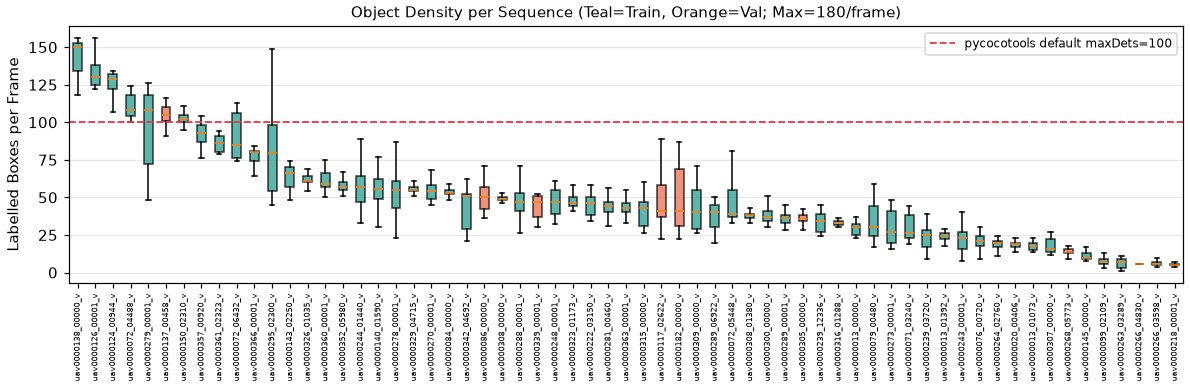

split,test,train,val
res_bucket,,,
1904x1071,0,12895,459
1344x756,441,5645,827
2688x1512,0,3505,233
1360x765,0,962,0
1920x1080,991,721,0
2720x1530,0,473,349
1360x764,1474,0,0
1904x1072,305,0,0
3840x2160,0,0,978


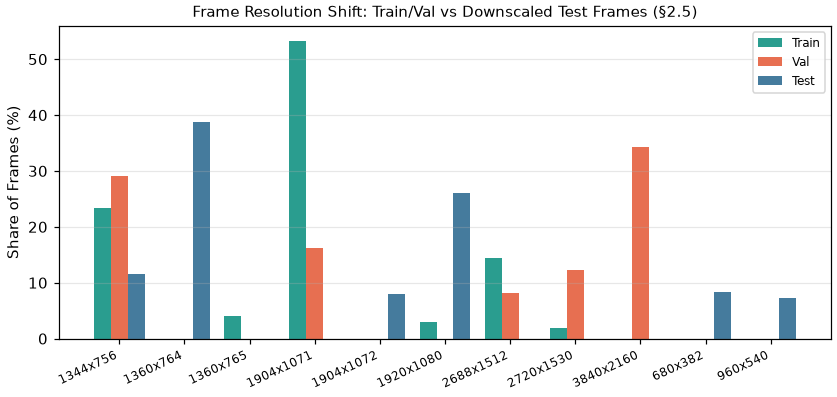

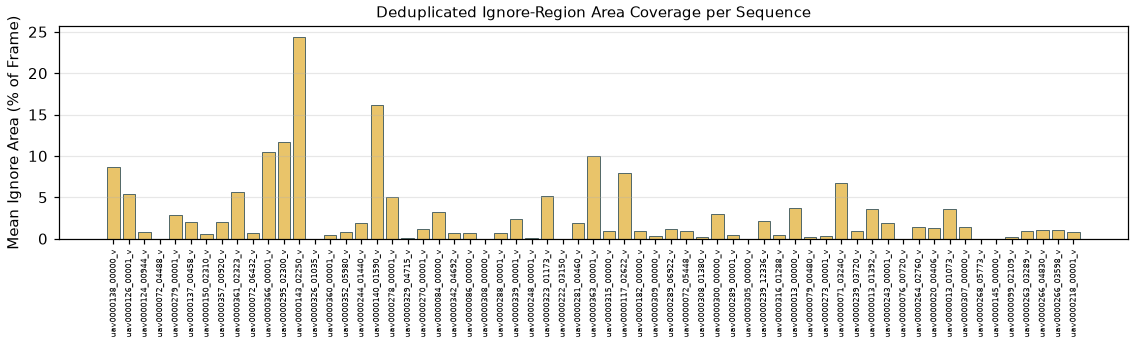

In [8]:
dens = (manifest_df[manifest_df["split"] != "test"].groupby(["split", "clip"])["n_boxes"]
        .agg(["mean", "max"]).round(1).sort_values("mean", ascending=False))
print("Densest sequences (boxes / frame):")
display(dens.head(10))
print("Max boxes in a single frame:", int(manifest_df["n_boxes"].max()))
show_image("eda_density_per_clip.png", 800)

res = manifest_df.groupby(["split", "res_bucket"]).size().rename("frames").reset_index()
display(res.pivot(index="res_bucket", columns="split", values="frames").fillna(0).astype(int)
        .sort_values("train", ascending=False))
show_image("eda_resolutions.png", 750)
show_image("eda_ignore_coverage.png", 750)

### 3.4 Temporal redundancy → frame step `k`

,lag_k,n_pairs,median_iou,p25_iou,p75_iou,median_disp_px,median_rel_disp
0,1,1097628,0.8967,0.7912,0.9674,2.00,0.0291
1,2,1090077,0.8095,0.6333,0.9324,3.91,0.0557
2,3,1082554,0.7313,0.5065,0.9003,5.70,0.0830
4,5,1067598,0.5973,0.3177,0.8421,9.43,0.1375
7,8,1045470,0.4398,0.1373,0.7626,15.04,0.2196
9,10,1031089,0.3567,0.0599,0.7143,18.79,0.2738
19,20,961789,0.1020,0.0000,0.5255,36.24,0.5310


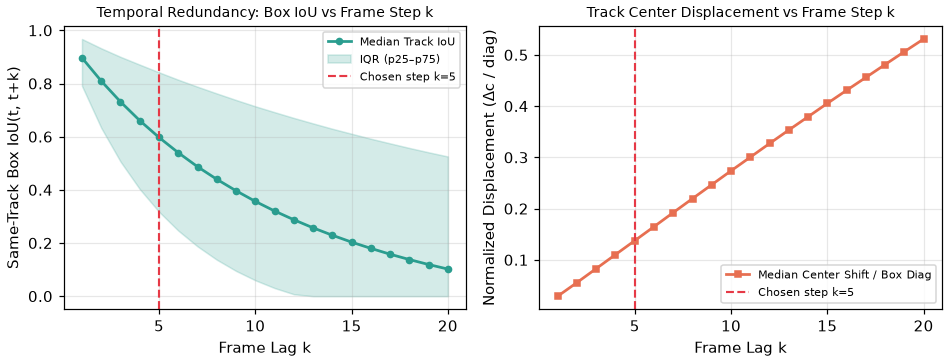

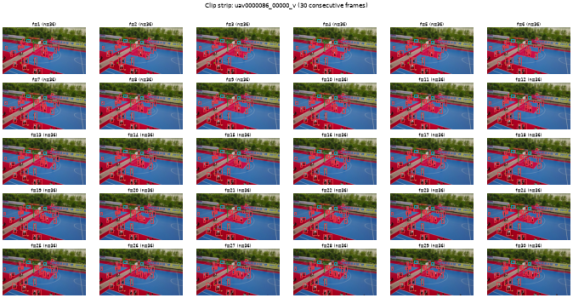

In [9]:
lag_df = pd.read_csv(P.cache / "redundancy_lag_k.csv")
display(lag_df[lag_df["lag_k"].isin([1, 2, 3, 5, 8, 10, 20])])
show_image("eda_frame_step_redundancy.png", 750)
show_image("clip_strip_uav0000086_00000_v.png", 900)

## 4. Training caches

`k5_drop_L1920` (protocol), `k5_blur_L1920` (ablation arm, notebook 02), `k2_drop_L1920` (denser frames, notebooks 04/05).

,cache,train,val
0,k5_drop_L1920,4868,571
1,k5_blur_L1920,4868,571
2,k2_drop_L1920,12114,571


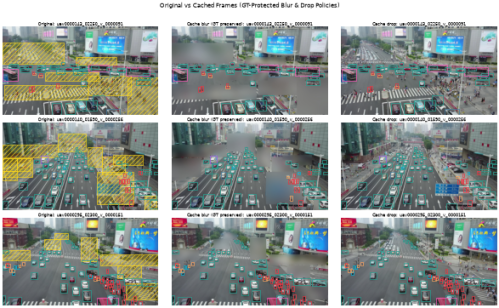

In [10]:
from vdet.data.cache import build_cache_from_recipe

CACHE_RECIPES = {
    "k5_drop_L1920": dict(cache_name="k5_drop_L1920", frame_step_k=5, val_frame_step_k=5, long_side=1920,
                          ignore_policy="drop", gt_dilate_px=2, feather_px=6, jpeg_quality=95,
                          num_workers=8, splits=["train", "val"]),
    "k5_blur_L1920": dict(cache_name="k5_blur_L1920", frame_step_k=5, val_frame_step_k=5, long_side=1920,
                          ignore_policy="blur", gt_dilate_px=2, feather_px=6, jpeg_quality=95,
                          num_workers=8, splits=["train", "val"]),
    "k2_drop_L1920": dict(cache_name="k2_drop_L1920", frame_step_k=2, val_frame_step_k=5, long_side=1920,
                          ignore_policy="drop", gt_dilate_px=2, feather_px=6, jpeg_quality=92,
                          num_workers=8, splits=["train", "val"], seed=42),
}

rows = []
for name, recipe in CACHE_RECIPES.items():
    idx_path = P.cache / name / "index.parquet"
    if not idx_path.exists():
        build_cache_from_recipe(recipe=recipe, data_root=P.data, cache_root=P.cache)   # CPU, ~minutes
    idx = pd.read_parquet(idx_path)
    rows.append({"cache": name, **idx.groupby("split").size().to_dict()})
display(pd.DataFrame(rows))
show_image("cache_vs_original.png", 900)

## 5. K-means anchors (train split only)

In [11]:
from vdet.models.anchors import fit_kmeans_anchors

anchors = fit_kmeans_anchors(use_cached_yaml=True)   # refits from boxes if cache/kmeans_anchors_L1280.yaml is missing
print("Anchor sizes per FPN level (px @1280):", anchors["sizes"])
print("Aspect ratios:", anchors["aspect_ratios"][0])
print(f"Mean best IoU of train boxes: COCO default anchors = {anchors['mean_best_iou_default']:.3f} "
      f"-> fitted anchors = {anchors['mean_best_iou_fitted']:.3f}")

Anchor sizes per FPN level (px @1280): ((10, 15, 16), (20, 23, 26), (26, 29, 33), (39, 43, 45), (66, 66, 109))
Aspect ratios: (0.58, 1.06, 1.92)
Mean best IoU of train boxes: COCO default anchors = 0.648 -> fitted anchors = 0.819
